# 01. Exploratory Data Analysis (EDA)

Notebook ini memeriksa metadata, distribusi kelas, karakteristik gambar TIFF, dan kualitas data sebelum modeling.

**Alur analisis:** load dataset > dataset overview > distribusi kelas > visualisasi gambar > dimensi dan rasio aspek > integritas data > pemeriksaan preprocessing > train-validation split > format submission.

EDA menggunakan **metadata training asli** untuk pemeriksaan kualitas data. 

## 1. Import Libraries and Scripts

In [4]:
from pathlib import Path
import sys
import zipfile

WORK_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()

def add_project_scripts():
    search_dirs = [Path.cwd(), Path.cwd().parent, WORK_DIR]
    for parent in search_dirs:
        if (parent / 'scripts' / 'dataset.py').is_file():
            sys.path.insert(0, str(parent.resolve()))
            return parent
    input_dir = Path('/kaggle/input')
    if input_dir.exists():
        for file in sorted(input_dir.rglob('scripts/dataset.py')):
            parent = file.parent.parent
            sys.path.insert(0, str(parent))
            return parent
        archives = sorted(input_dir.rglob('scripts.zip'))
        if archives:
            destination = WORK_DIR / 'project_code'
            destination.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(archives[0]) as archive:
                archive.extractall(destination)
            if not (destination / 'scripts' / 'dataset.py').is_file():
                raise FileNotFoundError('scripts.zip must contain scripts/dataset.py')
            sys.path.insert(0, str(destination))
            return destination
    raise FileNotFoundError(
        'scripts package not found. Attach scripts.zip through Kaggle Add Input, '
        'or run this notebook inside the GitHub project directory.')

PROJECT_CODE = add_project_scripts()
print('Scripts loaded from:', PROJECT_CODE)

Scripts loaded from: /kaggle/input/datasets/sharlizmayz/scripts-document-classification


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

from scripts.dataset import (find_data_dir,load_metadata,find_image_root,make_train_val_split,split_fingerprint,
    ResizeWithPadding,build_transform,)

sns.set_theme(style="whitegrid")
print("Loaded shared scripts from:", PROJECT_CODE)

Loaded shared scripts from: /kaggle/input/datasets/sharlizmayz/scripts-document-classification


## 2. Load Dataset

In [6]:
DATA_DIR = find_data_dir()

train_df = pd.read_csv(DATA_DIR / "train.csv")

clean_train_df, test_df, sample_submission, class_names, excluded_count = load_metadata(DATA_DIR)

TRAIN_DIR = find_image_root(DATA_DIR, train_df.iloc[0]["filename"])
TEST_DIR = find_image_root(DATA_DIR, test_df.iloc[0]["filename"])

print("Data directory:", DATA_DIR)
print("Image roots:", TRAIN_DIR, "|", TEST_DIR)
print("Raw train:", train_df.shape)
print("Clean train for modeling:", clean_train_df.shape)
print("Excluded unreadable images:", excluded_count)
print("Test:", test_df.shape)
print("Sample submission:", sample_submission.shape)
display(train_df.head())

Data directory: /kaggle/input/competitions/document-image-classification-sd234504
Image roots: /kaggle/input/competitions/document-image-classification-sd234504/train | /kaggle/input/competitions/document-image-classification-sd234504/test
Raw train: (32003, 4)
Clean train for modeling: (32002, 4)
Excluded unreadable images: 1
Test: (7994, 2)
Sample submission: (7994, 2)


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


## 3. Dataset Overview

In [7]:
print("Training data information:")
train_df.info()

print("\nMissing values:")
display(train_df.isnull().sum().to_frame("missing_values"))

print("Duplicate training IDs:", train_df["id"].duplicated().sum())
print("Duplicate training filenames:", train_df["filename"].duplicated().sum())

Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32003 entries, 0 to 32002
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          32003 non-null  object
 1   filename    32003 non-null  object
 2   class_name  32003 non-null  object
 3   label       32003 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 1000.2+ KB

Missing values:


,missing_values
id,0
filename,0
class_name,0
label,0


Duplicate training IDs: 0
Duplicate training filenames: 0


## 4. Class Distribution
Melihat jumlah gambar pada masing-masing kelas untuk mengetahui apakah distribusi target relatif seimbang.

,image_count
class_name,
advertisement,2012
budget,2004
email,2013
file_folder,2022
form,2005
handwritten,2026
invoice,1982
letter,1972
memo,1994


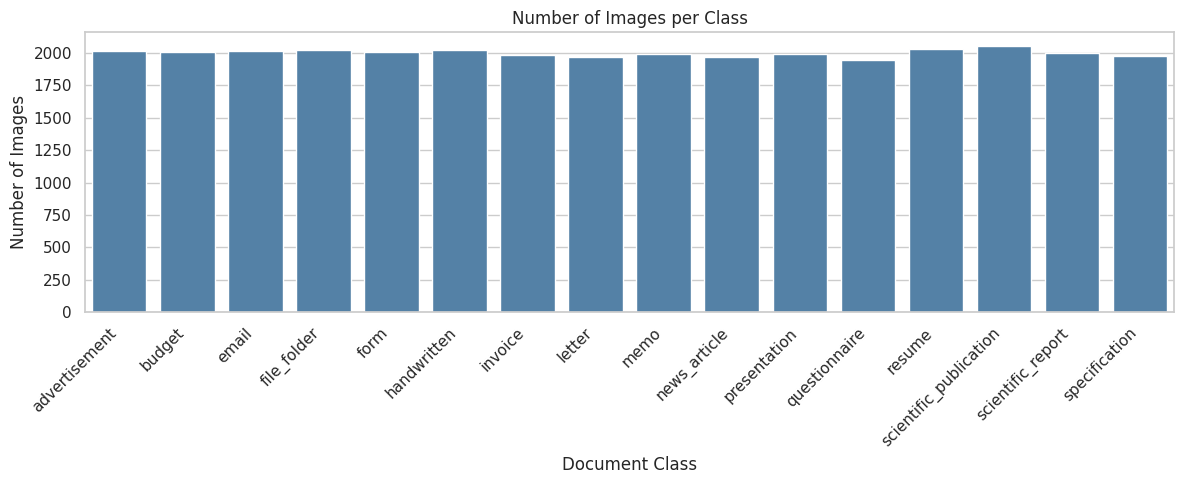

Minimum: 1948
Maximum: 2056


In [8]:
class_counts = train_df["class_name"].value_counts().sort_index()

display(class_counts.to_frame("image_count"))

plt.figure(figsize=(12, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Number of Images per Class")
plt.xlabel("Document Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Minimum:", class_counts.min())
print("Maximum:", class_counts.max())

## 5. Image Visualization

Menampilkan satu dokumen dari setiap kelas. 

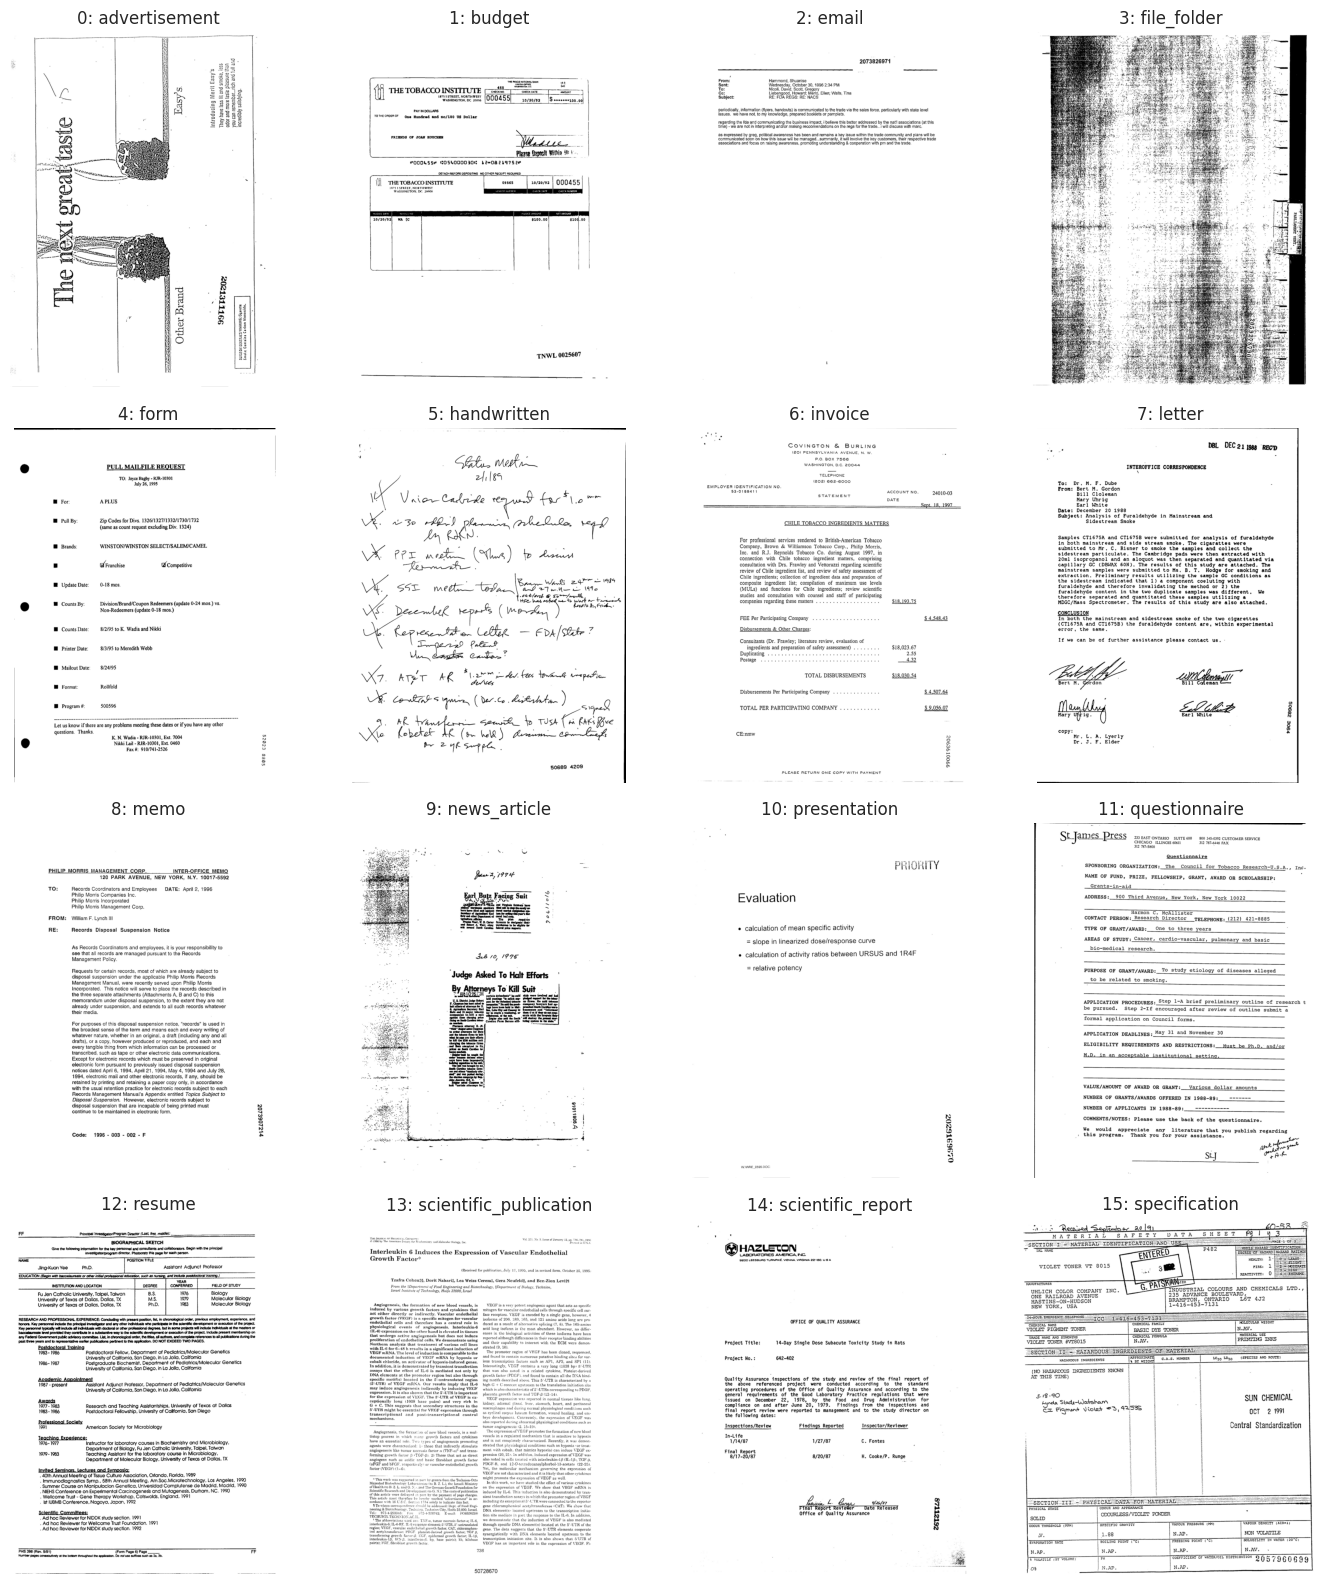

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(14, 16))

for label, ax in enumerate(axes.flat):
    sample = train_df[train_df["label"] == label].iloc[0]
    image_path = TRAIN_DIR / sample["filename"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(f'{label}: {sample["class_name"]}')
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Image Properties
Memeriksa ukuran, rasio aspek, mode warna, dan format gambar menggunakan sampel kecil dari setiap kelas.

In [10]:
# Ambil 5 gambar dari setiap kelas agar pemeriksaan tetap ringan
image_samples = (
    clean_train_df.groupby("label", group_keys=False)
    .sample(n=5, random_state=42))

image_info = []

for _, row in image_samples.iterrows():
    image_path = TRAIN_DIR / row["filename"]

    with Image.open(image_path) as image:
        width, height = image.size
        image_info.append({
            "class_name": row["class_name"],
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "mode": image.mode,
            "format": image.format})

image_info_df = pd.DataFrame(image_info)

display(image_info_df[["width", "height", "aspect_ratio"]].describe().round(2))
display(image_info_df["mode"].value_counts().to_frame("count"))
display(image_info_df["format"].value_counts().to_frame("count"))

,width,height,aspect_ratio
count,80.0,80.0,80.00
mean,766.6,1000.0,0.77
std,20.5,0.0,0.02
min,726.0,1000.0,0.73
25%,754.0,1000.0,0.75
50%,762.0,1000.0,0.76
75%,777.0,1000.0,0.78
max,871.0,1000.0,0.87


,count
mode,
L,80


,count
format,
TIFF,80


## 7. Image Dimension and Aspect Ratio Distribution
Memeriksa dimensi seluruh gambar training untuk memahami variasi resolusi dan orientasi dokumen. Aspect ratio dihitung sebagai `width / height`: nilai di bawah 1 menunjukkan portrait, sedangkan nilai di atas 1 menunjukkan landscape.

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


Successfully read: 32002
Unreadable images: 1


,width,height,aspect_ratio
count,32002.00,32002.0,32002.00
mean,766.34,1000.0,0.77
std,27.78,0.0,0.03
min,606.00,1000.0,0.61
25%,754.00,1000.0,0.75
50%,762.00,1000.0,0.76
75%,777.00,1000.0,0.78
max,2542.00,1000.0,2.54


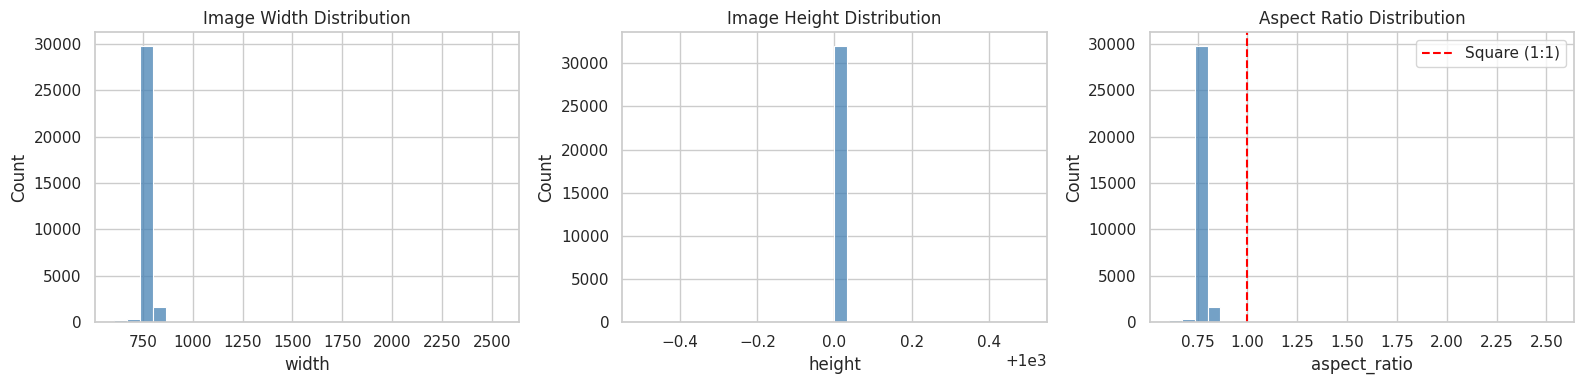

Portrait images: 31981
Square images: 0
Landscape images: 21

Examples of unreadable files:


,filename,error
0,train/scientific_publication/2500126531_250012...,cannot identify image file '/kaggle/input/comp...


In [17]:
dimension_info = []
unreadable_files = []

for _, row in train_df.iterrows():
    image_path = TRAIN_DIR / row["filename"]

    try:
        with Image.open(image_path) as image:
            width, height = image.size

            dimension_info.append({
                "filename": row["filename"],
                "width": width,
                "height": height,
                "aspect_ratio": width / height})

    except Exception as error:
        unreadable_files.append({
            "filename": row["filename"],
            "error": str(error)})

dimension_df = pd.DataFrame(dimension_info)

print(f"Successfully read: {len(dimension_df)}")
print(f"Unreadable images: {len(unreadable_files)}")

display(dimension_df[["width", "height", "aspect_ratio"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=dimension_df, x="width", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Image Width Distribution")

sns.histplot(data=dimension_df, x="height", bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Image Height Distribution")

sns.histplot(data=dimension_df, x="aspect_ratio", bins=30, ax=axes[2], color="steelblue")
axes[2].axvline(1, color="red", linestyle="--", label="Square (1:1)")
axes[2].set_title("Aspect Ratio Distribution")
axes[2].legend()

plt.tight_layout()
plt.show()

print("Portrait images:", (dimension_df["aspect_ratio"] < 1).sum())
print("Square images:", (dimension_df["aspect_ratio"] == 1).sum())
print("Landscape images:", (dimension_df["aspect_ratio"] > 1).sum())

if unreadable_files:
    print("\nExamples of unreadable files:")
    display(pd.DataFrame(unreadable_files).head(10))


## 8. Visual Variation per Class
Menampilkan beberapa contoh acak dari setiap kelas agar variasi layout dan tampilan dokumen dapat diamati.

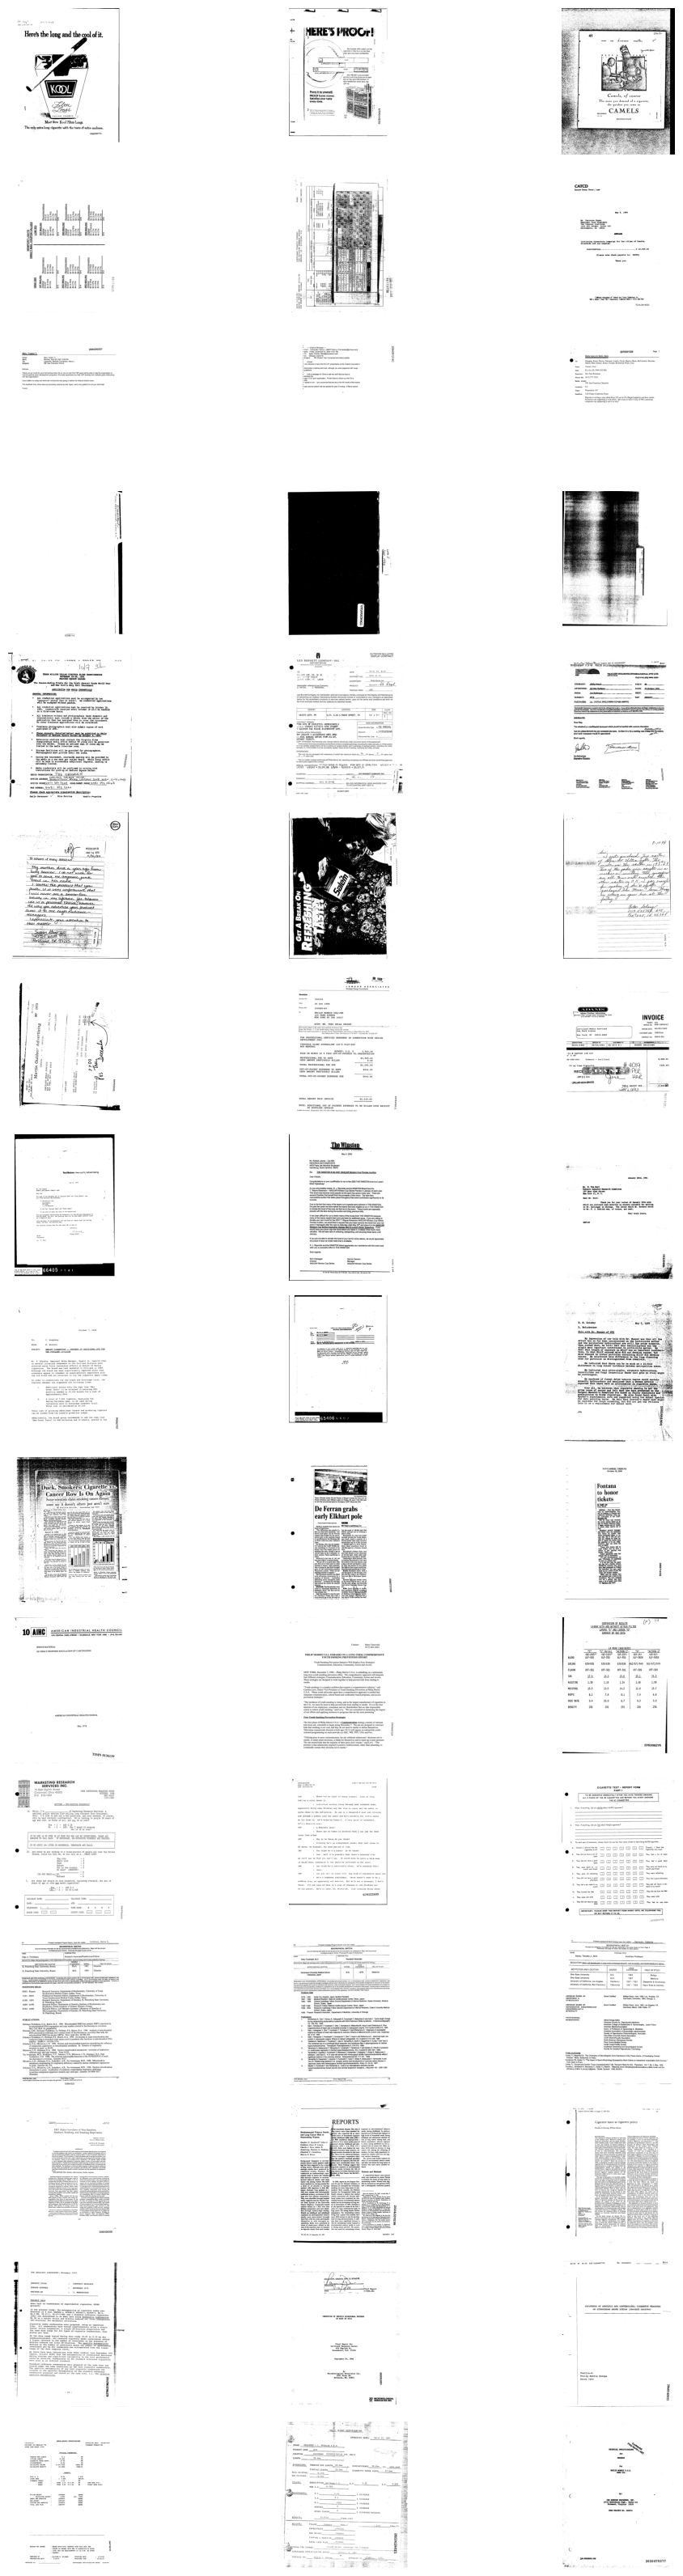

In [18]:
n_samples_per_class = 3
visual_samples = (
    clean_train_df.groupby("class_name", group_keys=False)
    .sample(n=n_samples_per_class, random_state=42))

fig, axes = plt.subplots(len(train_df["class_name"].unique()), n_samples_per_class, figsize=(12, 32))

for row_index, (class_name, group) in enumerate(visual_samples.groupby("class_name", sort=True)):
    for col_index, (_, row) in enumerate(group.iterrows()):
        image_path = TRAIN_DIR / row["filename"]
        with Image.open(image_path) as image:
            axes[row_index, col_index].imshow(image.convert("RGB"))
        axes[row_index, col_index].axis("off")
        if col_index == 0:
            axes[row_index, col_index].set_ylabel(class_name, rotation=0, labelpad=65, va="center")

plt.tight_layout()
plt.show()

## 9. Image Integrity Check
Memeriksa apakah file gambar training dan test dapat dibuka dan diverifikasi oleh PIL.

In [19]:
def check_image_files(dataframe, image_dir):
    corrupted_files = []

    for filename in dataframe["filename"]:
        image_path = image_dir / filename
        try:
            with Image.open(image_path) as image:
                image.verify()
        except Exception:
            corrupted_files.append(filename)

    return corrupted_files

corrupted_train = check_image_files(train_df, TRAIN_DIR)
corrupted_test = check_image_files(test_df, TEST_DIR)

print(f"Corrupted/unreadable training images: {len(corrupted_train)}")
print(f"Corrupted/unreadable test images: {len(corrupted_test)}")

if corrupted_train:
    print("Training examples:", corrupted_train[:10])
if corrupted_test:
    print("Test examples:", corrupted_test[:10])

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


Corrupted/unreadable training images: 1
Corrupted/unreadable test images: 0
Training examples: ['train/scientific_publication/2500126531_2500126536.tif']


## 10. Preprocessing Preview


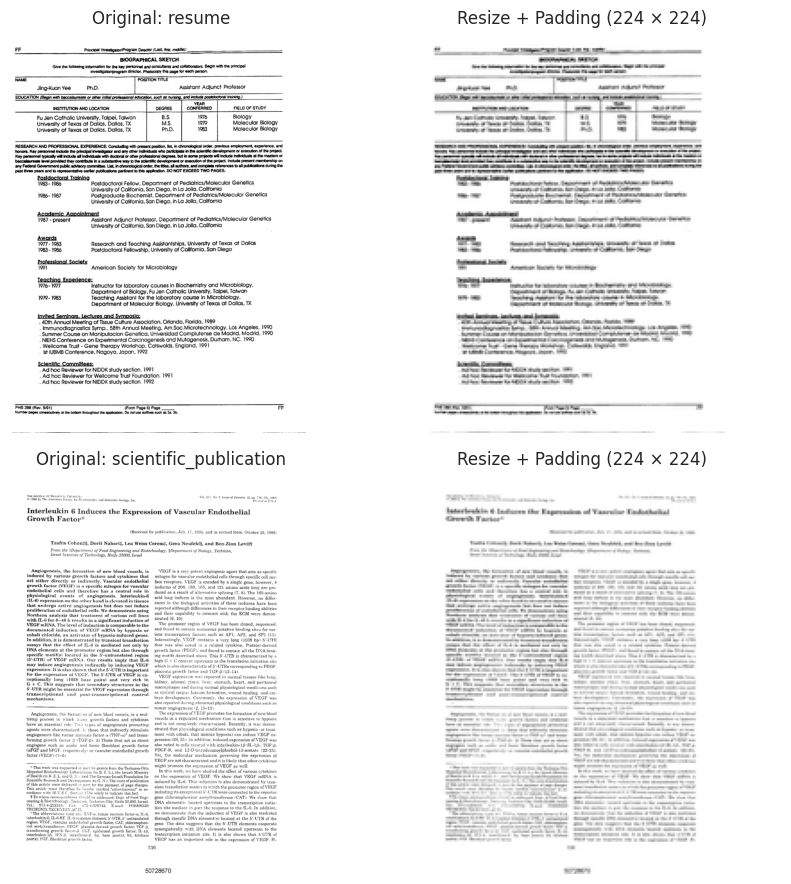

Validation tensor shape: (3, 224, 224)


In [20]:
IMAGE_SIZE = 224
sample_rows = clean_train_df.drop_duplicates("label").head(2)
figure, axes = plt.subplots(len(sample_rows), 2, figsize=(9, 9), squeeze=False)

for index, (_, row) in enumerate(sample_rows.iterrows()):
    image_path = TRAIN_DIR / row["filename"]
    with Image.open(image_path) as image:
        original = image.convert("RGB")
        processed = ResizeWithPadding(IMAGE_SIZE)(original)

    axes[index, 0].imshow(original)
    axes[index, 0].set_title(f"Original: {row['class_name']}")
    axes[index, 1].imshow(processed)
    axes[index, 1].set_title(f"Resize + Padding ({IMAGE_SIZE} × {IMAGE_SIZE})")
    for axis in axes[index]:
        axis.axis("off")

plt.tight_layout()
plt.show()

with Image.open(TRAIN_DIR / sample_rows.iloc[0]["filename"]) as image:
    validation_tensor = build_transform(IMAGE_SIZE, training=False)(image.convert("RGB"))
print("Validation tensor shape:", tuple(validation_tensor.shape))

## 11. Training and Validation Split

Notebook modeling memakai **stratified 80:20 split** dengan `random_state=42`.

In [21]:
SEED = 42
train_part, val_part = make_train_val_split(clean_train_df, valid_size=0.20, seed=SEED)

print("Training images:", len(train_part))
print("Validation images:", len(val_part))
print("Shared image IDs:", len(set(train_part["id"]) & set(val_part["id"])))
print("Validation split fingerprint:", split_fingerprint(val_part))

class_split = pd.DataFrame({
    "train": train_part["class_name"].value_counts(),
    "validation": val_part["class_name"].value_counts(),
}).fillna(0).astype(int).sort_index()
display(class_split)

assert set(train_part["id"]).isdisjoint(val_part["id"])
assert len(train_part) + len(val_part) == len(clean_train_df)

Training images: 25601
Validation images: 6401
Shared image IDs: 0
Validation split fingerprint: 114f3f66d060f8ba


,train,validation
class_name,,
advertisement,1610,402
budget,1603,401
email,1610,403
file_folder,1617,405
form,1604,401
handwritten,1621,405
invoice,1586,396
letter,1578,394
memo,1595,399


## 12. Submission File Check

Memastikan ID pada `test.csv` dan `sample_submission.csv` cocok sehingga prediksi di notebook `03_submission.ipynb` dapat disusun dengan urutan yang benar.

In [22]:
print("Test IDs are unique:", test_df["id"].is_unique)
print("Submission IDs are unique:", sample_submission["id"].is_unique)
print("Same number of rows:", len(test_df) == len(sample_submission))
print("Same ID order:", test_df["id"].equals(sample_submission["id"]))
print("Submission columns:", sample_submission.columns.tolist())

Test IDs are unique: True
Submission IDs are unique: True
Same number of rows: True
Same ID order: True
Submission columns: ['id', 'label']


## 13. Summary

- Dataset terdiri atas 16 kelas dokumen, dengan distribusi kelas yang relatif seimbang.
- Citra dokumen memiliki resolusi dan rasio aspek yang bervariasi; sebagian besar berorientasi portrait.
- Pemeriksaan integritas menemukan satu gambar training yang tidak dapat dibaca. Pipeline modeling mengeluarkan gambar tersebut secara konsisten.
- Untuk menghindari perubahan bentuk dokumen, modeling menggunakan **resize with white padding** sebelum normalisasi ImageNet.
- Setelah pembersihan, stratified split 80:20 digunakan untuk seluruh eksperimen pada `02_modeling.ipynb`.

Tahap selanjutnya adalah `02_modeling.ipynb`.